# 03 · Can unocculted starspots or faculae on an M dwarf fake (or hide) an atmosphere?

Unocculted spots make the transit chord brighter than the disk average, so the measured depth is inflated by a wavelength-dependent factor $\epsilon(\lambda)$ (the transit light source effect; Rackham et al. 2018). For cool M dwarfs the spot/photosphere contrast carries molecular bands (H$_2$O, TiO), so the stellar signal can mimic a planetary absorption feature. Here we ask how big that signal is compared to Lazuli's error bars, and whether a featureless planet could be "detected" as having water.

**Instrument / code:** Lazuli IFS, `lazuli_exo.observe(..., f_spot, f_fac)` (Rackham 2018 eq. 2 with PHOENIX spectra, `lazuli_exo.star.contamination`) and `lazuli_exo.star.TLSE_PRESETS`.

## Prompt to try in Jupyter AI

> Using `lazuli_exo`, investigate the transit light source effect for the M-dwarf planets "TRAPPIST-1 e" and "GJ 1214 b".
> `lazuli_exo.observe(planet, scenario, n_transits, R=100, f_spot=..., f_fac=...)` multiplies the model depth by the Rackham et al. (2018) contamination factor; literature covering fractions are in `lazuli_exo.star.TLSE_PRESETS`.
> (1) Take the "flat" (featureless) scenario, add spots for f_spot from 0 to 0.4, and compute `obs.detect()` template S/N and H2O band S/N per transit: can spots alone fake an H2O detection?
> (2) For the "clear" scenario, compare spot-free vs spotted spectra and express the peak-to-peak contamination (depth*(eps-1)) in units of the per-bin error bar for 1 and 10 transits.
> Make a two-panel figure: left, the TRAPPIST-1 e spectra (clear immaculate vs flat+spots vs flat+spots+faculae) with error bars; right, the spurious S/N vs f_spot for both hosts with a line at S/N = 5.
> Print the spot and facula temperatures the code assumes, and state the model's limitations.

## Setup

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
# plt.style.use('gks')

import lazuli_exo
from lazuli_exo.star import TLSE_PRESETS
from lazuli_exo.targets import get_target

HOSTS = {'TRAPPIST-1 e': 'M_late_solar', 'GJ 1214 b': 'M_mid_solar'}   # planet -> literature preset for its host
THUMB = Path('thumbs/03_stellar_contamination.png')
for p, key in HOSTS.items():
    print(f"{p:13s} host T_eff = {get_target(p)['T_eff_K']:.0f} K; preset {key} = {TLSE_PRESETS[key]}, with faculae: {TLSE_PRESETS[key + '_fac']}")

TRAPPIST-1 e  host T_eff = 2566 K; preset M_late_solar = {'f_spot': 0.39, 'f_fac': 0.0}, with faculae: {'f_spot': 0.39, 'f_fac': 0.3}
GJ 1214 b     host T_eff = 3101 K; preset M_mid_solar = {'f_spot': 0.12, 'f_fac': 0.0}, with faculae: {'f_spot': 0.12, 'f_fac': 0.3}


## The contamination factor $\epsilon(\lambda)$

Defaults: $T_\mathrm{spot} = 0.86\,T_\mathrm{eff}$ for M dwarfs, $T_\mathrm{fac} = T_\mathrm{eff} + 100$ K. The planet's spectrum enters only as a multiplicative factor, so the contamination signal is $\delta\,(\epsilon - 1)$.

In [2]:
def spotted(planet, scenario='clear', n=1, **tlse):
    return lazuli_exo.observe(planet, scenario, n_transits=n, R=100, **tlse)

for p, key in HOSTS.items():
    for label, tlse in (('spots', TLSE_PRESETS[key]), ('spots+faculae', TLSE_PRESETS[key + '_fac'])):
        o0, o1 = spotted(p), spotted(p, **tlse)
        info = o1.meta['atmosphere']['tlse']
        ptp = np.ptp(o1.depth - o0.depth)
        print(f"{p:13s} {label:14s} T_spot = {info['T_spot_K']:.0f} K, T_fac = {info['T_fac_K']:.0f} K, eps = {info['eps_min']:.3f}-{info['eps_max']:.3f}; "
              f"contamination ptp = {ptp*1e6:5.0f} ppm = {ptp/np.median(o0.depth_err):4.1f} sigma/bin (1 transit), "
              f"{ptp/np.median(o0.depth_err/np.sqrt(10)):4.1f} sigma/bin (10 transits); "
              f"planet H2O-model ptp = {o0.meta['atmosphere']['feature_amplitude_ppm']:.0f} ppm")

TRAPPIST-1 e  spots          T_spot = 2207 K, T_fac = 2666 K, eps = 1.137-1.634; contamination ptp =  2394 ppm =  4.2 sigma/bin (1 transit), 13.4 sigma/bin (10 transits); planet H2O-model ptp = 3138 ppm
TRAPPIST-1 e  spots+faculae  T_spot = 2207 K, T_fac = 2666 K, eps = 0.571-1.439; contamination ptp =  3425 ppm =  6.1 sigma/bin (1 transit), 19.2 sigma/bin (10 transits); planet H2O-model ptp = 3138 ppm
GJ 1214 b     spots          T_spot = 2667 K, T_fac = 3201 K, eps = 1.037-1.135; contamination ptp =  1238 ppm =  5.9 sigma/bin (1 transit), 18.7 sigma/bin (10 transits); planet H2O-model ptp = 4705 ppm
GJ 1214 b     spots+faculae  T_spot = 2667 K, T_fac = 3201 K, eps = 0.629-1.131; contamination ptp =  1510 ppm =  7.2 sigma/bin (1 transit), 22.8 sigma/bin (10 transits); planet H2O-model ptp = 4705 ppm


## Can spots fake an atmosphere?

Start from a featureless planet (`flat` scenario, template S/N = 0 by construction) and add unocculted spots. Any S/N that `detect()` now reports is purely stellar.

In [3]:
f_grid = np.array([0.0, 0.01, 0.03, 0.05, 0.08, 0.12, 0.2, 0.3, 0.39])
fake = {}
for p in HOSTS:
    dets = [spotted(p, 'flat', f_spot=f).detect() for f in f_grid]
    fake[p] = np.array([(d['template_snr_diagonal'], d['band_snr']['H2O']) for d in dets])
    print(p)
    for f, (tpl, h2o) in zip(f_grid, fake[p]):
        print(f"   f_spot = {f:4.2f}: spurious template S/N = {tpl:6.2f}, spurious H2O band S/N = {h2o:6.2f}  (1 transit)")
    i5 = np.argmax(fake[p][:, 0] >= 5)
    print(f"   -> spurious template S/N >= 5 in one transit from f_spot = {f_grid[i5]:.2f}" if fake[p][i5, 0] >= 5 else "   -> never reaches S/N 5")

TRAPPIST-1 e
   f_spot = 0.00: spurious template S/N =   0.00, spurious H2O band S/N =   0.00  (1 transit)
   f_spot = 0.01: spurious template S/N =   0.20, spurious H2O band S/N =   0.10  (1 transit)
   f_spot = 0.03: spurious template S/N =   0.61, spurious H2O band S/N =   0.32  (1 transit)
   f_spot = 0.05: spurious template S/N =   1.04, spurious H2O band S/N =   0.54  (1 transit)
   f_spot = 0.08: spurious template S/N =   1.71, spurious H2O band S/N =   0.88  (1 transit)
   f_spot = 0.12: spurious template S/N =   2.68, spurious H2O band S/N =   1.38  (1 transit)
   f_spot = 0.20: spurious template S/N =   4.89, spurious H2O band S/N =   2.48  (1 transit)
   f_spot = 0.30: spurious template S/N =   8.27, spurious H2O band S/N =   4.14  (1 transit)
   f_spot = 0.39: spurious template S/N =  12.09, spurious H2O band S/N =   5.95  (1 transit)
   -> spurious template S/N >= 5 in one transit from f_spot = 0.30


GJ 1214 b
   f_spot = 0.00: spurious template S/N =   0.00, spurious H2O band S/N =   0.00  (1 transit)
   f_spot = 0.01: spurious template S/N =   1.14, spurious H2O band S/N =   0.39  (1 transit)
   f_spot = 0.03: spurious template S/N =   3.51, spurious H2O band S/N =   1.20  (1 transit)
   f_spot = 0.05: spurious template S/N =   5.98, spurious H2O band S/N =   2.04  (1 transit)
   f_spot = 0.08: spurious template S/N =   9.90, spurious H2O band S/N =   3.35  (1 transit)
   f_spot = 0.12: spurious template S/N =  15.56, spurious H2O band S/N =   5.22  (1 transit)
   f_spot = 0.20: spurious template S/N =  28.63, spurious H2O band S/N =   9.40  (1 transit)
   f_spot = 0.30: spurious template S/N =  49.06, spurious H2O band S/N =  15.62  (1 transit)
   f_spot = 0.39: spurious template S/N =  72.71, spurious H2O band S/N =  22.41  (1 transit)
   -> spurious template S/N >= 5 in one transit from f_spot = 0.05


## Hero figure

Left: what Lazuli would see for TRAPPIST-1 e in 4 transits, for a real H$_2$-rich clear atmosphere on a quiet star versus a bare rock (flat) on a spotted star. Right: spurious template S/N from spots alone, one transit.

clear atmosphere, quiet star        median sigma/bin (lambda > 0.6 um, 4 transits) = 130 ppm


flat planet, spots (f_{spot} = 0.39) median sigma/bin (lambda > 0.6 um, 4 transits) = 130 ppm
flat planet, spots + faculae        median sigma/bin (lambda > 0.6 um, 4 transits) = 130 ppm


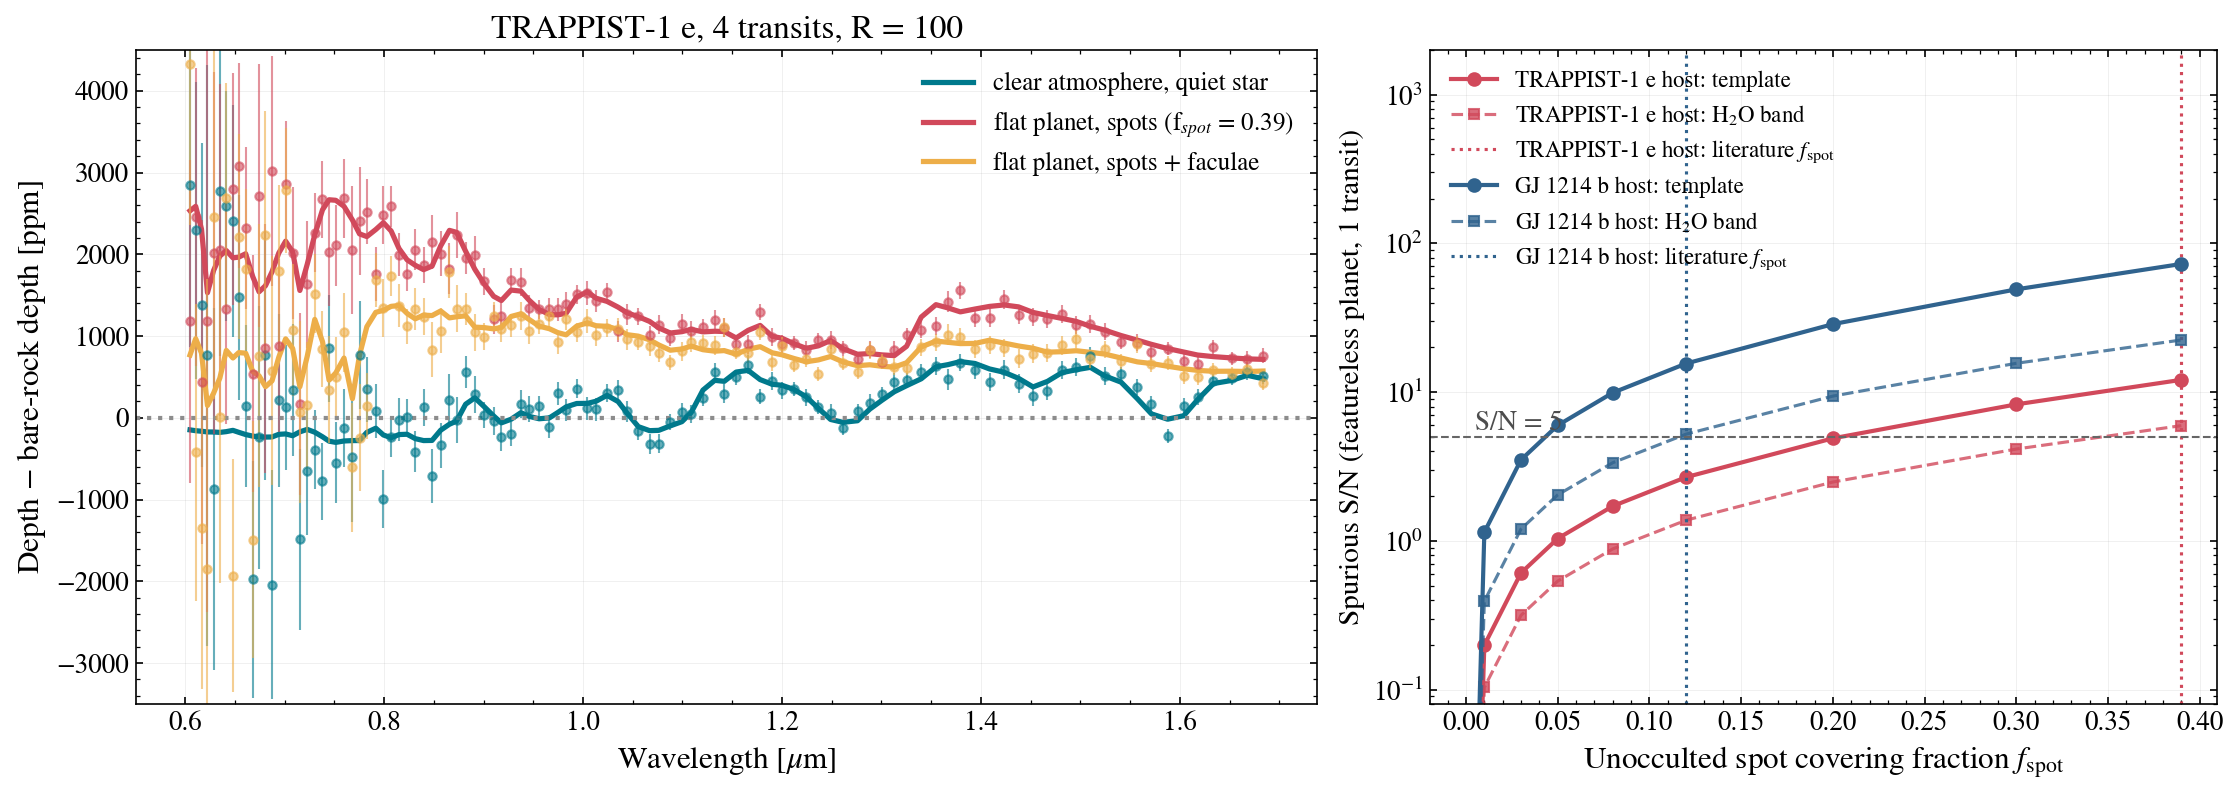

In [4]:
N_SHOW = 4
fig, (ax, bx) = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
p = 'TRAPPIST-1 e'
cases = [('clear atmosphere, quiet star', spotted(p, 'clear', N_SHOW), '#00798c'),
         (f"flat planet, spots (f$_{{spot}}$ = {TLSE_PRESETS['M_late_solar']['f_spot']})", spotted(p, 'flat', N_SHOW, **TLSE_PRESETS['M_late_solar']), '#d1495b'),
         ('flat planet, spots + faculae', spotted(p, 'flat', N_SHOW, **TLSE_PRESETS['M_late_solar_fac']), '#edae49')]
flat = spotted(p, 'flat').depth.mean()
WL_MIN = 0.6   # TRAPPIST-1 is so red that the bluest bins have error bars of 10^4-10^5 ppm; leave them off the plot
for i, (lab, o, c) in enumerate(cases):
    m = o.wavelength >= WL_MIN
    pts = o.simulate_points(seed=i)
    ax.errorbar(o.wavelength[m], (pts - flat)[m] * 1e6, yerr=o.depth_err[m] * 1e6, fmt='o', ms=4, color=c, alpha=0.6, capsize=0, lw=1)
    ax.plot(o.wavelength[m], (o.depth - flat)[m] * 1e6, color=c, lw=2.5, label=lab)
    print(f"{lab.replace('$', ''):35s} median sigma/bin (lambda > {WL_MIN} um, {N_SHOW} transits) = {np.median(o.depth_err[m])*1e6:.0f} ppm")
ax.set_ylim(-3500, 4500)
ax.axhline(0, color='0.55', ls=':')
ax.set_xlabel('Wavelength [$\\mu$m]', fontsize=15)
ax.set_ylabel('Depth $-$ bare-rock depth [ppm]', fontsize=15)
ax.set_title(f'{p}, {N_SHOW} transits, R = 100', fontsize=16)
ax.legend(fontsize=12, loc='upper right')
ax.tick_params(labelsize=13)

for (pl, arr), c in zip(fake.items(), ('#d1495b', '#30638e')):
    bx.plot(f_grid, arr[:, 0], 'o-', color=c, label=f'{pl} host: template')
    bx.plot(f_grid, arr[:, 1], 's--', color=c, ms=5, lw=1.5, alpha=0.8, label=f'{pl} host: H$_2$O band')
    pf = TLSE_PRESETS[HOSTS[pl]]['f_spot']
    bx.axvline(pf, color=c, ls=':', lw=1.5, label=f'{pl} host: literature $f_\mathrm{{spot}}$')
bx.set_yscale('log'); bx.set_ylim(0.08, 2000)
bx.axhline(5, color='0.4', ls='--', lw=1)
bx.text(0.005, 5.6, 'S/N = 5', color='0.3', fontsize=13)
bx.set_xlabel('Unocculted spot covering fraction $f_\\mathrm{spot}$', fontsize=15)
bx.set_ylabel('Spurious S/N (featureless planet, 1 transit)', fontsize=14)
bx.legend(fontsize=11, loc='upper left', ncol=1)
bx.tick_params(labelsize=13)
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

**Yes, spots alone can fake a signal.** On TRAPPIST-1 (late-M preset, $f_\mathrm{spot}$ = 0.39, $T_\mathrm{spot}$ = 2207 K) the contamination is 2394 ppm peak-to-peak, 4.2σ per bin in a single transit and comparable to the 3138 ppm feature of an H$_2$-rich clear atmosphere; a featureless TRAPPIST-1 e would show a spurious template S/N of 12.1 (H$_2$O band 6.0) in one transit. GJ 1214's brighter host is even more exposed: $f_\mathrm{spot}$ = 0.05 already gives a spurious template S/N of 6.0 per transit, and the mid-M preset ($f_\mathrm{spot}$ = 0.12) gives 15.6 (H$_2$O band 5.2), a 1238 ppm, 5.9σ-per-bin contamination. Adding faculae ($f_\mathrm{fac}$ = 0.3) pushes ε below 1 in places (ε = 0.57–1.44 for TRAPPIST-1), so contamination can also suppress the apparent depth rather than only add features.

## Caveats & next steps

- **Simple contamination model**: Rackham et al. (2018) eq. 2 with a single spot and a single facula temperature, PHOENIX spectra on a solar-metallicity grid (floor 2000 K), no limb-darkening dependence, no occulted spots, no time variability between transits. Real spot contrasts and covering fractions for TRAPPIST-1 are uncertain by large factors; the presets are literature ranges, not measurements.
- **The planet model is still the fast isothermal surrogate**, and the M-dwarf PHOENIX SEDs are too bright in the blue, so the blue-end noise here is ~10–25 % optimistic.
- **Template S/N is a ranking statistic**, not a detection significance; "fake detection" here means the spectrum is inconsistent with a flat line, not that a retrieval would confidently claim H$_2$O.
- *Extend it:* (1) fit the spotted flat spectrum with the clear-atmosphere template plus an $\epsilon(\lambda)$ term and see how much the spot and planet parameters are degenerate; (2) let $f_\mathrm{spot}$ vary randomly from transit to transit and see how stacking behaves; (3) use the 0.4–0.6 µm range, where the spot signal is strongest and H$_2$O is absent, as a contamination diagnostic and check how many transits it needs.